In [ ]:
#!/usr/bin/env python3
import os
import numpy as np
import matplotlib.pyplot as plt

# -----------------------
# Files (USRP capture)
# -----------------------
# Set this to your loopback_full_duplex output directory
dir = "/home/risc/ram/USRP/usrp_software/usrp_n210/data/usrp_runs/Jan29/"  # change as needed

iq_file   = os.path.join(dir, "rx_iq_sc16_10msps_static_10s.bin")
meta_csv  = os.path.join(dir, "rx_meta_10msps_static_10s.csv")

fs = 10.0e6  # Hz (RX sample rate)
fc = 900e6  # Hz (RX center frequency)
# -----------------------
# Analysis settings
# -----------------------
seconds_to_plot = 8.     # time-domain plot window (seconds)
skip_seconds    = 1.01     # skip initial transient (seconds)
max_samples     = None     # limit complex samples after conversion

# DDC settings
remove_dc_after_ddc = False
use_estimated_fb    = False

# If you know your injected tone:
fb = 100e3          # Hz (TX baseband tone)
avg_N = 2500

# Plotting
plotRawIQ_constln = False
plotIQ_time       = False
plotDDC_IQ        = False
plot_phase        = True

Meta blocks: 0, total_samps_logged=0, nonzero_err_blocks=0
Loaded 104999924 complex samples (10.500 s) from /home/risc/ram/USRP/usrp_software/usrp_n210/data/usrp_runs/Jan29/rx_iq_sc16_10msps_static_10s.bin
Estimated frequency (sanity): 99983.2153 Hz
Using fb from metadata: 100000.000 Hz


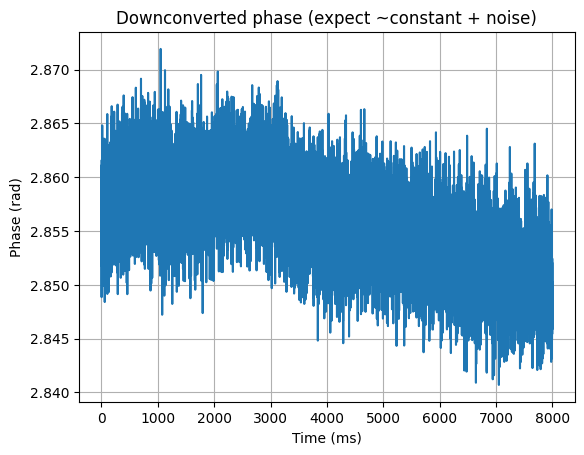

(94899924,)
Mean and std dev of measured phase: (np.float32(2.8557966), np.float32(0.004535559))


In [5]:
# -----------------------
# Load metadata (CSV from UHD)
# -----------------------
def load_meta_csv(meta_csv_path):
    """
    Reads CSV with columns:
      seq,nsamps,has_time,time_full,time_frac,err_code
    Returns dict with arrays and some convenience counts.
    """
    data = np.genfromtxt(meta_csv_path, delimiter=",", names=True, dtype=None, encoding=None)
    meta = {
        "seq": data["seq"].astype(np.int64),
        "nsamps": data["nsamps"].astype(np.int64),
        "has_time": data["has_time"].astype(np.int64),
        "time_full": data["time_full"].astype(np.int64),
        "time_frac": data["time_frac"].astype(np.float64),
        "err_code": data["err_code"].astype(np.int64),
    }
    meta["num_blocks"] = meta["seq"].size
    meta["total_samps_logged"] = int(np.sum(meta["nsamps"]))
    meta["num_err"] = int(np.sum(meta["err_code"] != 0))
    return meta


meta_blocks = load_meta_csv(meta_csv)

print(f"Meta blocks: {meta_blocks['num_blocks']}, total_samps_logged={meta_blocks['total_samps_logged']}, nonzero_err_blocks={meta_blocks['num_err']}")
# -----------------------
# Helper: robust IQ loader (USRP sc16)
# -----------------------
def load_usrp_sc16_as_complex64(iq_file_path, max_samples=None, normalize=True):
    """
    UHD sc16: interleaved int16 IQ: [I0,Q0,I1,Q1,...]
    Returns complex64 normalized to ~[-1,1) if normalize=True
    """
    raw = np.fromfile(iq_file_path, dtype=np.int16)
    if raw.size < 2:
        raise ValueError("File too short to contain IQ data.")
    if raw.size % 2 != 0:
        raw = raw[:-1]
    iq = raw.reshape(-1, 2)
    I = iq[:, 0].astype(np.float32)
    Q = iq[:, 1].astype(np.float32)

    if normalize:
        x = (I + 1j * Q) / 32768.0
    else:
        x = (I + 1j * Q)

    x = x.astype(np.complex64)
    if max_samples is not None:
        x = x[:max_samples]
    return x

# -----------------------
# Load IQ
# -----------------------
x = load_usrp_sc16_as_complex64(iq_file, max_samples=max_samples, normalize=True)
N0 = len(x)
print(f"Loaded {N0} complex samples ({N0/fs:.3f} s) from {iq_file}")

# Sanity: compare file samples vs metadata sum (should match closely)
if meta_blocks["total_samps_logged"] > 0:
    diff = N0 - meta_blocks["total_samps_logged"]
    print(f"Sample count CHECK: file - meta_sum = {diff} samples")
    # Small differences can happen if you ever changed writer logic; large differences = mismatch


# -----------------------
# Skip initial transient
# -----------------------
skip = int(skip_seconds * fs)
if skip >= N0:
    raise ValueError("skip_seconds is too large for the file length.")
x = x[skip:]
N = len(x)

# -----------------------
# Helper: frequency estimate
# -----------------------
def estimate_tone_freq(x, fs, nfft=2**18):
    """Estimate dominant tone frequency using FFT peak (coarse but effective).""" 
    n = min(len(x), nfft) 
    xw = x[:n] * np.hanning(n) 
    X = np.fft.fftshift(np.fft.fft(xw)) 
    f = np.fft.fftshift(np.fft.fftfreq(n, d=1/fs)) 
    k = np.argmax(np.abs(X)) 
    return float(f[k])

fb_hat = estimate_tone_freq(x, fs)

if use_estimated_fb:
    print(f"Estimated tone frequency: {fb_hat:.4f} Hz")
    fb_used = fb_hat
else:
    fb_used = fb
    print(f"Estimated frequency (sanity): {fb_hat:.4f} Hz")
    print(f"Using fb from metadata: {fb_used:.3f} Hz")

# -----------------------
# Plot raw I/Q (time domain)
# -----------------------
M = int(seconds_to_plot * fs)
M = min(M, N)
t = np.arange(M) / fs

if plotIQ_time:
    plt.figure(figsize=(5, 5))
    plt.plot(t * 1e3, np.real(x[:M]), label="I (real)")
    plt.plot(t * 1e3, np.imag(x[:M]), label="Q (imag)")
    plt.xlabel("Time (ms)")
    plt.ylabel("Amplitude")
    plt.title("Raw RX IQ")
    plt.legend()
    plt.grid(True)
    plt.show()

if plotRawIQ_constln:
    plt.figure(figsize=(5, 5))
    plt.scatter( np.real(x[:M]), np.imag(x[:M]), s=4, alpha=0.5 )
    plt.xlabel("I")
    plt.ylabel("Q")
    plt.title("Raw IQ (from Rx samples)")
    plt.grid(True)
    plt.show()

# -----------------------
# Digital downconversion (wipe off fb -> DC)
# -----------------------
n = np.arange(N, dtype=np.float64)
lo = np.exp(-1j * 2.0 * np.pi * (fb_used-0.00) * n / fs).astype(np.complex64)
y = x * lo
phi_raw = np.unwrap(np.angle(y[:M]))
y_abs = np.abs(y[:M])

if plot_phase:
    plt.figure()
    plt.plot((t * 1e3)[::5000], phi_raw[::5000], label="Phase from raw samples")
    plt.xlabel("Time (ms)")
    plt.ylabel("Phase (rad)")
    plt.title("Downconverted phase (expect ~constant + noise)")
    plt.grid(True)
    plt.show()

# plot iq constellation
print(y.shape)
if plotDDC_IQ:
    plt.figure(figsize=(5, 5))
    plt.scatter( np.real(y[:M][::2000]), np.imag(y[:M][::2000]), s=4, alpha=0.5 )
    plt.xlabel("I")
    plt.ylabel("Q")
    plt.title("Downconverted IQ (from Rx samples)")
    plt.grid(True)
    plt.show()

phi_std = np.std(phi_raw)
phi_mean = np.mean(phi_raw)

print(f"Mean and std dev of measured phase: {phi_mean, phi_std}")

# Estimate phase change
$\Delta \phi = \frac{4 \pi}{\lambda} \Delta R$ where $\lambda = \frac{c}{f}$

When $f = 250 \, \mathrm{MHz}$, for $\Delta R = 1 \, \text{mm}$; requires a phase resolution of $\Delta \phi = 10.4 \, \text{mrad}$.

When $f = 100 \, \mathrm{MHz}$, for $\Delta R = 1 \, \text{mm}$; requires a phase resolution of $\Delta \phi = 4.2 \, \text{mrad}$.

At 250 MHz, a phase resolution of 1e-3 rad, can get us a range resolution of 95.427 micron (if measurements are noise free).

In [12]:
fc_tx = float(meta["fc_tx"]+meta["bb_tone"])
# fc_tx = 100e6
c = 299_792_458.0

# dR = 0.0233  # 1 inch in meters
dR_inch = 0.025
dR_mmm =  dR_inch * 0.0254 * 1e3
lam = c / fc_tx
print(dR_mmm, fc_tx)

dphi_round = 4 * np.pi * dR_mmm * 1e-3 / lam   # round-trip


print("Expected dphi round-trip (rad):", dphi_round)
# print("Observed dphi:",  (2.5 + dphi_round) %(2*np.pi))

d_phi_res = 1e0
dR_res = d_phi_res * lam * 0.25 / np.pi

print(f"For phase resolution of {d_phi_res*1e0:.3f} rad, we get a range res of {dR_res*1e2:.3f} cm")

0.635 900078125.0
Expected dphi round-trip (rad): 0.023957588072140438
For phase resolution of 1.000 rad, we get a range res of 2.651 cm


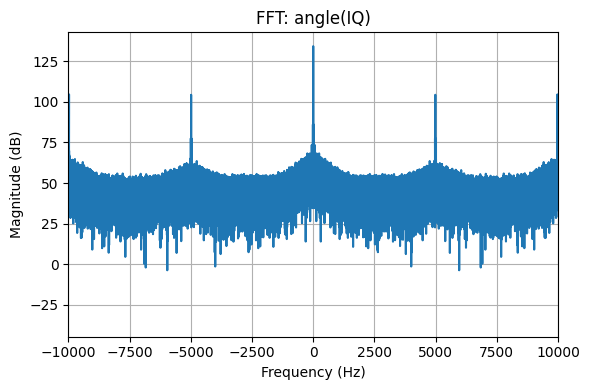

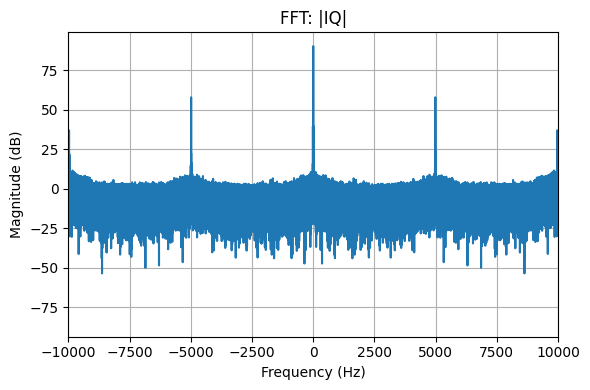

In [29]:
def plot_fft(x, fs, f_center, title, fspan=None):
    x = np.asarray(x)
    # x = x - np.mean(x)

    N = len(x)
    win = np.hanning(N)
    X = np.fft.fftshift(np.fft.fft(x * win)) 
    f = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))
    
    # X = np.fft.rfft(x * win) 
    # f = np.fft.rfftfreq(N, 1/fs)

    mag = 20 * np.log10(np.maximum(np.abs(X), 1e-12))

    plt.figure(figsize=(6, 4))
    plt.plot(f, mag)
    plt.grid(True)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.title(title)

    if fspan is not None:
        plt.xlim(f_center - fspan, f_center + fspan)

    plt.tight_layout()
    plt.show()

plot_fft(
    phi_raw,        # real or imag are equivalent here
    fs,
    f_center=0e3,
    title="FFT: angle(IQ)",
    fspan=10e3            # inspect up to 2 kHz
)

plot_fft(
    y_abs,        # real or imag are equivalent here
    fs,
    f_center=0e3,
    title="FFT: |IQ|",
    fspan=10e3            # inspect up to 2 kHz
)


In [60]:
M_new = int(229500 * 1e-3 * 10e6) # for trimming the data when phase slips
print(y[M_new])

(-0.4765625-1.453125j)


# Lowpass filters
1. Received signal is at 10 MSPS - noisy and oversampled. 
2. We filter the high-frequency noise and decimate to lower the sampling rate.
3. Choose the passband (fp), stopband (fsb), and fs_out

Example: For a monotone of 1 kHz. Fp has to be greater than  1 kHz. Stopband slightly above, say 1.8 kHz. Fs_out must be greater than 2*1 kHz. 

factors = [100, 5]                 # 10 MHz / 100 -> 100 kHz / 5 -> 20 kHz

Check the frequency response of the phase signal and tune these parameters accordingly.

--- Decimation chain start: Fs=2.000 MSPS ---
Stage 1: /10 |    2000.0 kHz ->     200.0 kHz | taps=173
Stage 2: / 4 |     200.0 kHz ->      50.0 kHz | taps=515
--- Decimation chain end: Fs=50.000 kSPS ---


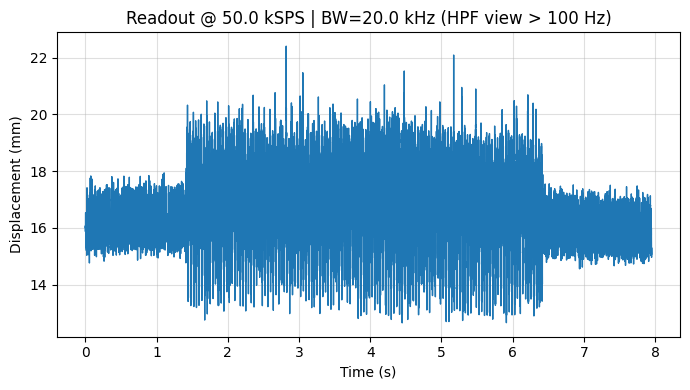

In [30]:
import matplotlib.pyplot as plt
from scipy.signal import kaiserord, firwin, upfirdn, filtfilt, butter, sosfiltfilt, welch, detrend

# ==============================================================================
# 1. INSTRUMENT CONFIGURATION & PHYSICS
# ==============================================================================
FS_INPUT       = fs          # 20 MSPS
FS_INSTRUMENT  = 50e3        # final readout rate: 20 kSPS
BW_MEASUREMENT = 20e3         # your "flat" measurement BW inside final Nyquist (<= 10 kHz recommended at 20 kSPS)
VIEW_HPF_CUTOFF = 100.0      # for plotting only
FINAL_TRANS_HZ = 1000.0       # adjust as needed

fp_final = BW_MEASUREMENT
fsb_final = BW_MEASUREMENT + FINAL_TRANS_HZ


y_complex = y[:M]

# Decimation: 10e6 -> 50e3
# 20e6 -> 1e6 -> 100e3 -> 50e3
factors = [10, 4]        # 20 MSPS /20=1 MSPS /10=100 kSPS /5=20 kSPS

# Physics constants
C_LIGHT = 3e8
F_MOD   = fc + fb
K_RAD_TO_METER = C_LIGHT / (4 * np.pi * F_MOD)

# ==============================================================================
# 2. FILTER DESIGN HELPERS
# ==============================================================================
def design_kaiser_lpf(fs, fp_hz, fsb_hz, attenuation_db=100):
    """
    Kaiser-window FIR LPF.
    fp_hz  : passband edge (Hz)
    fsb_hz : stopband edge (Hz) (must be > fp_hz)
    """
    nyq = 0.5 * fs
    if not (0 < fp_hz < fsb_hz < nyq):
        raise ValueError(f"Bad edges: fp={fp_hz}, fsb={fsb_hz}, nyq={nyq}")

    width = (fsb_hz - fp_hz) / nyq
    numtaps, beta = kaiserord(attenuation_db, width)
    if numtaps % 2 == 0:
        numtaps += 1

    # Place cutoff in the middle of the transition band
    fc = 0.5 * (fp_hz + fsb_hz)
    taps = firwin(numtaps, fc, fs=fs, window=("kaiser", beta))
    return taps

def decimate_stage_fir(x, fs_in, M, fp_keep_hz, attenuation_db=100, guard_frac=0.10):
    """
    FIR anti-alias + decimate by M.
    fp_keep_hz : content you want to preserve through this stage (Hz).
    guard_frac : fraction of new Nyquist reserved for transition band.
    """
    fs_out = fs_in / M
    nyq_out = 0.5 * fs_out

    # Passband edge: keep what we need, but never exceed something comfortable below nyq_out
    fp = min(fp_keep_hz, 0.45 * fs_out)

    # Stopband edge: new Nyquist (where aliasing starts)
    # Build a transition band that ends at nyq_out, starts at fp
    # If fp is too close to nyq_out, force a minimum transition using guard_frac
    min_fp = (1.0 - guard_frac) * nyq_out
    if fp > min_fp:
        fp = min_fp

    fsb = nyq_out

    taps = design_kaiser_lpf(fs_in, fp_hz=fp, fsb_hz=fsb, attenuation_db=attenuation_db)

    # Polyphase-friendly decimation using upfirdn
    y = upfirdn(taps, x, up=1, down=M)

    # Trim FIR group delay in output-rate samples:
    gd_in = (len(taps) - 1) // 2
    gd_out = int(np.ceil(gd_in / M))
    if 2 * gd_out < len(y):
        y = y[gd_out:-gd_out]

    return y, fs_out, taps

def apply_decimation_chain(x, fs_in, factors, bw_meas_hz, attenuation_db=100):
    """
    Multi-stage decimation where each stage only preserves bw_meas_hz (plus margin),
    ensuring strong anti-aliasing without giant early filters.
    """
    cur_fs = fs_in
    y = x

    print(f"--- Decimation chain start: Fs={cur_fs/1e6:.3f} MSPS ---")
    for i, M in enumerate(factors, 1):
        # Keep slightly more than final BW so the last-stage spec FIR has room
        fp_keep = bw_meas_hz * 1.25

        y, next_fs, taps = decimate_stage_fir(
            y, fs_in=cur_fs, M=M, fp_keep_hz=fp_keep,
            attenuation_db=attenuation_db, guard_frac=0.10
        )

        print(f"Stage {i}: /{M:>2} | {cur_fs/1e3:>9.1f} kHz -> {next_fs/1e3:>9.1f} kHz | taps={len(taps)}")
        cur_fs = next_fs

    print(f"--- Decimation chain end: Fs={cur_fs/1e3:.3f} kSPS ---")
    return y, cur_fs

# ==============================================================================
# 3. PROCESSING PIPELINE
# ==============================================================================
y_decim, fs_final = apply_decimation_chain(
    y_complex, FS_INPUT, factors, bw_meas_hz=BW_MEASUREMENT, attenuation_db=100
)

if abs(fs_final - FS_INSTRUMENT) > 1e-6:
    print(f"WARNING: fs_final={fs_final} Hz does not match FS_INSTRUMENT={FS_INSTRUMENT} Hz")

# Final "spec" LPF at final rate (strong, flexible)
# Choose a transition width that actually fits: at 20 kSPS, Nyquist=10 kHz
# So BW_MEASUREMENT must be < 10 kHz. Transition should fit before 10 kHz.

if fsb_final <= fp_final:
    raise ValueError("Final filter transition doesn't fit. Reduce BW_MEASUREMENT or FINAL_TRANS_HZ, or raise fs_final.")

b_final = design_kaiser_lpf(fs_final, fp_hz=fp_final, fsb_hz=fsb_final, attenuation_db=120)

# zero-phase offline
y_clean = filtfilt(b_final, 1.0, y_decim)

# guard trim for filtfilt edge effects
L = len(b_final)
guard = 3 * (L - 1)
if 2 * guard < len(y_clean):
    y_clean = y_clean[guard:-guard]

# Phase -> displacement
phi_rad = np.unwrap(np.angle(y_clean))
disp_meters = phi_rad * K_RAD_TO_METER

# View-only HPF
# sos_hp = butter(4, VIEW_HPF_CUTOFF, btype="highpass", fs=fs_final, output="sos")
# disp_view_mm = sosfiltfilt(sos_hp, disp_meters) * 1e3

disp_view_mm = disp_meters * 1e3

# ==============================================================================
# 4. PLOTS
# ==============================================================================
t = np.arange(len(disp_view_mm)) / fs_final

plt.figure(figsize=(7, 4))
# light decimation for plotting
step = max(1, int(fs_final // 2000))
plt.plot(t[::step], disp_view_mm[::step], linewidth=1.0)
plt.xlabel("Time (s)")
plt.ylabel("Displacement (mm)")
plt.title(f"Readout @ {fs_final/1e3:.1f} kSPS | BW={BW_MEASUREMENT/1e3:.1f} kHz (HPF view > {VIEW_HPF_CUTOFF:.0f} Hz)")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

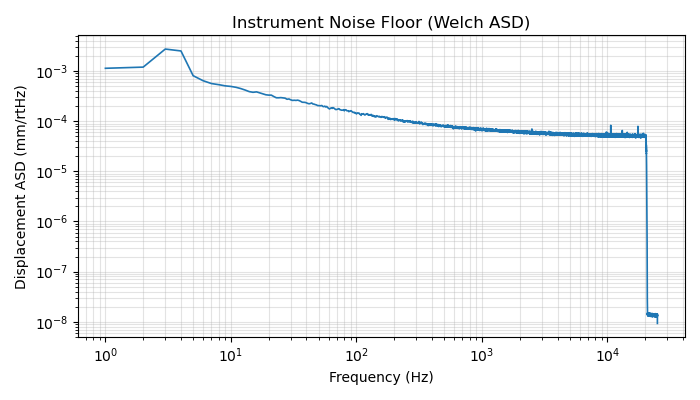

In [63]:
# Noise floor ASD (displacement) via Welch
SEGMENT_TIME = 1.0
nperseg = int(fs_final * SEGMENT_TIME)
freqs, pxx = welch(disp_meters, fs=fs_final, nperseg=nperseg, detrend="linear", scaling="density")
asd_m_per_rtHz = np.sqrt(pxx)

plt.figure(figsize=(7, 4))
plt.loglog(freqs[1:], (asd_m_per_rtHz[1:] * 1e3), linewidth=1.2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Displacement ASD (mm/rtHz)")
plt.title("Instrument Noise Floor (Welch ASD)")
plt.grid(True, which="both", alpha=0.35)
plt.tight_layout()
plt.show()

# Playing phase as Audio

In [64]:
np.savez(
    "phaseNoise_10msps_limeSDR_loopback.npz",
    t=t,                     # seconds
    phi_rad=phi_rad,               # radians
    fs_final=fs_final,                   # Hz
    f_original = fs,                  # Hz
    BW_MEASUREMENT=BW_MEASUREMENT,             # Hz
    fsb_final = fsb_final,
    F_MOD = F_MOD,
    notes="20 mhz phase data from optical path, t and phi to compute displacement and get welch diagram: time series, phi_rad, fs_final, f_original, stopband final"
)

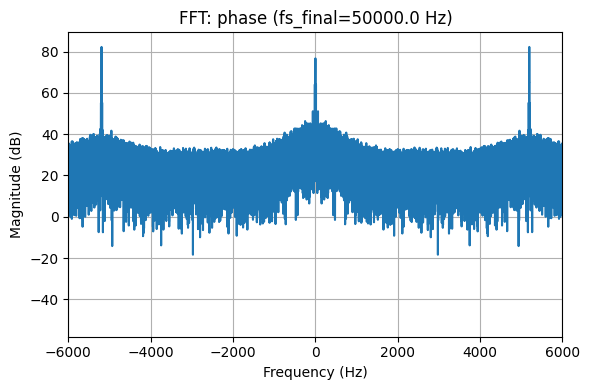

In [31]:
import sounddevice as sd
from scipy.signal import resample_poly, butter, filtfilt
from scipy.io.wavfile import write as wavwrite
from pathlib import Path

parent_path = Path("./Jan20/reconstruction/")

fs2audio = fs_final
phi2audio = phi_rad

audio_fname = "mary_lamb_indirect1_phase_recon"

def save_wav(filename, x_audio, fs):
    """
    Save audio to WAV file.
    x_audio must be float32 in [-1, 1].
    """
    # Convert to 16-bit PCM for compatibility
    x_int16 = np.int16(np.clip(x_audio, -1.0, 1.0) * 32767)
    wavwrite(filename, fs, x_int16)

    # Bandlimit into an audio-friendly band
    # High-pass removes drift; low-pass removes HF noise
def butter_filt(sig, fs, btype, cutoff_hz, order=4):
    nyq = 0.5 * fs
    wn = cutoff_hz / nyq
    b, a = butter(order, wn, btype=btype)
    return filtfilt(b, a, sig)

def phase_to_audio(
    phi,
    fs_phi,
    audio_fs,
    mode="ifreq",          # "phase" or "ifreq"
    hp_hz=50.0,            # high-pass to remove drift / DC in phase or ifreq
    lp_hz=5000.0,          # low-pass to keep audio band reasonable
    gain=0.9,              # overall volume scaling (0..1 typical)
    speed=1.0              # time-stretch: >1 faster/higher pitch, <1 slower/lower pitch
):
    """
    Convert phase readout to an audio waveform (float32 in [-1,1]).
    phi: phase samples in radians (preferably unwrapped)
    fs_phi: sample rate of phi (Hz)
    audio_fs: playback sample rate (Hz)
    mode:
      - "phase": listen to phase variation (after HP/LP)
      - "ifreq": listen to instantaneous frequency variation (dphi/dt), often clearer
    speed: playback speed factor (pitch shifts accordingly)
    """
    phi = np.asarray(phi, dtype=np.float64)

    # Handle unwrap if user forgot (safe)
    phi = np.unwrap(phi)

    # Remove mean (helps a lot)
    phi = phi - np.mean(phi)

    if mode.lower() == "ifreq":
        # Instantaneous frequency deviation proportional to derivative of phase:
        # dphi/dt / (2*pi)  -> Hz deviation (but we don't need absolute units for audio)
        x = np.diff(phi, prepend=phi[0]) * fs_phi / (2 * np.pi)
        fs_x = fs_phi
    elif mode.lower() == "phase":
        x = phi.copy()
        fs_x = fs_phi
    else:
        raise ValueError("mode must be 'phase' or 'ifreq'")

    # Optional time scaling (speed change)
    # Implement by resampling the signal in time
    if speed != 1.0 and speed > 0:
        # Speed up => fewer samples (higher pitch), slow down => more samples
        # resample_poly expects integer factors; approximate with rational
        # We'll do a simple resample using interpolation ratio
        n_new = int(len(x) / speed)
        n_new = max(n_new, 2)
        x = np.interp(
            np.linspace(0, len(x) - 1, n_new),
            np.arange(len(x)),
            x
        )
        fs_x = fs_x  # fs_x unchanged; we changed duration directly

    if hp_hz is not None and hp_hz > 0:
        x = butter_filt(x, fs_x, "highpass", hp_hz)

    if lp_hz is not None and lp_hz > 0 and lp_hz < 0.49 * fs_x:
        x = butter_filt(x, fs_x, "lowpass", lp_hz)

    # Resample to audio_fs
    # Use polyphase rational resampling (good quality)
    # Find integer up/down approximately (simple approach)
    # If fs_x is huge, this is still efficient.
    from math import gcd
    up = int(audio_fs)
    down = int(fs_x)
    g = gcd(up, down)
    up //= g
    down //= g
    x_audio = resample_poly(x, up, down)

    # Normalize to [-1, 1] and apply gain
    peak = np.max(np.abs(x_audio)) + 1e-12
    x_audio = (x_audio / peak) * gain
    x_audio = x_audio.astype(np.float32)

    return x_audio, audio_fs

def play_audio(x_audio, fs):
    sd.stop()
    sd.play(x_audio, fs, blocking=True)


# Listen to instantaneous frequency (usually more “audio-like”)
x_audio, audio_fs = phase_to_audio(
    phi = phi_rad,      # Use phi_clean, not undefined phi_hp
    fs_phi = fs2audio,
    audio_fs = 48000,     # Standard audio sample rate (or fs2audio if already 48k)
    mode = "phase",       # Velocity sounds more natural than displacement
    hp_hz = 0.0,         # Only remove DC/subsonic
    lp_hz = None,         # Don't double-filter
    gain = 0.7,
    speed = 1.0
)

plot_fft(
    x_audio,        # real or imag are equivalent here
    fs2audio,
    f_center=0.0,
    title=f"FFT: phase (fs_final={fs2audio:.1f} Hz)",
    fspan=6e3   # e.g. inspect up to 2 kHz around DC
)

parent_path.mkdir(parents=True, exist_ok=True)
# suffix =  str(meta_file).split("/")[-1].split("_")[2]

# save_wav(parent_path / f"{audio_fname}.wav", x_audio, int(fs2audio))